# Week 1 - Assignment 03
## Cleaning, Charts and Data Ethics

Domain: Healthcare

Objective: Clean the diabetes dataset, identify outliers,
visualize health indicators and examine possible dataset bias.

In [3]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# Download the CDC Diabetes Health Indicators dataset
dataset = fetch_ucirepo(id=891)

# Combine input features and target
df = pd.concat(
    [dataset.data.features, dataset.data.targets],
    axis=1
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (253680, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


## Step 2: Create a Working Copy

In [4]:
clean_df = df.copy()

print("Working copy created!")
print("Dataset shape:", clean_df.shape)

Working copy created!
Dataset shape: (253680, 22)


Step 3: Identify Missing Values

In [6]:
missing_values = clean_df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64

Total Missing Values: 0


## Step 4: Handle Missing Values

In [7]:
for col in clean_df.columns:
    if clean_df[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(clean_df[col]):
            clean_df[col] = clean_df[col].fillna(clean_df[col].median())
            print(col, "- Missing values filled using median.")
        else:
            clean_df[col] = clean_df[col].fillna("Unknown")
            print(col, "- Missing values filled using Unknown.")
    else:
        print(col, "- No missing values found.")

HighBP - No missing values found.
HighChol - No missing values found.
CholCheck - No missing values found.
BMI - No missing values found.
Smoker - No missing values found.
Stroke - No missing values found.
HeartDiseaseorAttack - No missing values found.
PhysActivity - No missing values found.
Fruits - No missing values found.
Veggies - No missing values found.
HvyAlcoholConsump - No missing values found.
AnyHealthcare - No missing values found.
NoDocbcCost - No missing values found.
GenHlth - No missing values found.
MentHlth - No missing values found.
PhysHlth - No missing values found.
DiffWalk - No missing values found.
Sex - No missing values found.
Age - No missing values found.
Education - No missing values found.
Income - No missing values found.
Diabetes_binary - No missing values found.


## Step 5: Detect and Handle Outliers

In [8]:
Q1 = clean_df["BMI"].quantile(0.25)
Q3 = clean_df["BMI"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = clean_df[
    (clean_df["BMI"] < lower_limit) |
    (clean_df["BMI"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

print("Decision: BMI outliers are retained because extreme BMI values")
print("may represent genuine health conditions rather than data-entry errors.")

Lower Limit: 13.5
Upper Limit: 41.5
Number of Outliers: 9847
Decision: BMI outliers are retained because extreme BMI values
may represent genuine health conditions rather than data-entry errors.


## Step 6: Inspect and Correct Data Types

In [ ]:
print("Before Correction:")
print(clean_df.dtypes)

categorical_columns = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "GenHlth",
    "DiffWalk", "Sex", "Education", "Income",
    "Diabetes_binary"
]

for col in categorical_columns:
    clean_df[col] = clean_df[col].astype("category")

print("\nAfter Correction:")
print(clean_df.dtypes)

## Step 7: Data Visualization and Charts

### Step 7.1: Histogram – BMI Distribution

Question: What is the distribution of BMI values among participants?

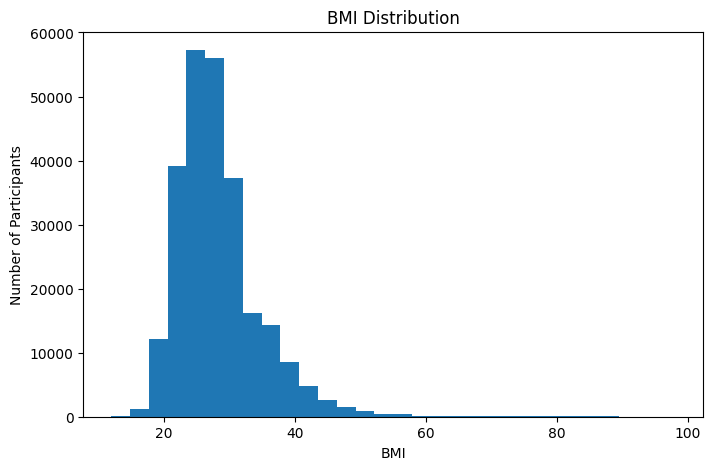

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(clean_df["BMI"], bins=30)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of Participants")

plt.show()

### Step 7.2: Bar Chart – Diabetes Status

Question: How many participants belong to each diabetes category?


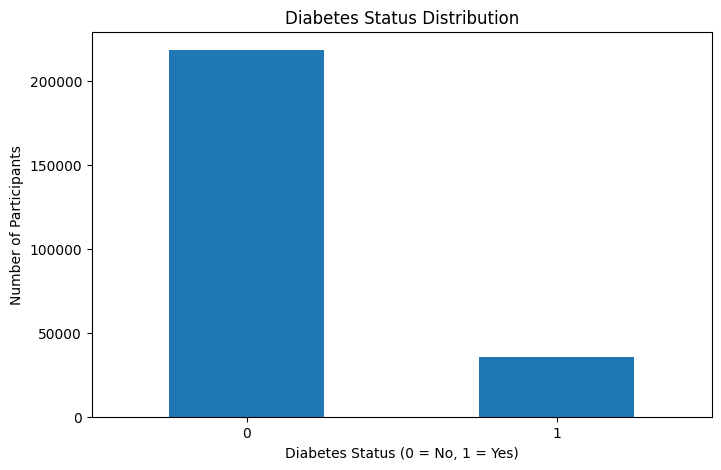

In [10]:
clean_df["Diabetes_binary"].value_counts().sort_index().plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Diabetes Status Distribution")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Participants")
plt.xticks(rotation=0)

plt.show()

### Step 7.3: Scatter Plot – BMI vs Physical Health

Question: Is there a relationship between BMI and physically unhealthy days?

In [ ]:
sample = clean_df.sample(2000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample["BMI"], sample["PhysHlth"], alpha=0.4)

plt.title("BMI vs Physical Health")
plt.xlabel("BMI")
plt.ylabel("Physically Unhealthy Days")

plt.show()

### Step 7.4: Bar Chart – Diabetes Status by Blood Pressure

Question: How does diabetes status vary among participants with and without high blood pressure?

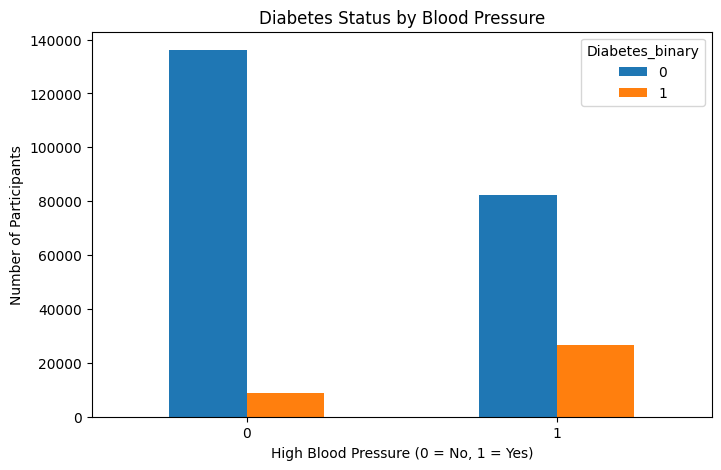

In [11]:
pd.crosstab(
    clean_df["HighBP"],
    clean_df["Diabetes_binary"]
).plot(kind="bar", figsize=(8, 5))

plt.title("Diabetes Status by Blood Pressure")
plt.xlabel("High Blood Pressure (0 = No, 1 = Yes)")
plt.ylabel("Number of Participants")
plt.xticks(rotation=0)

plt.show()

### Step 7.5: Bar Chart – General Health Ratings

Question: How do participants rate their general health?

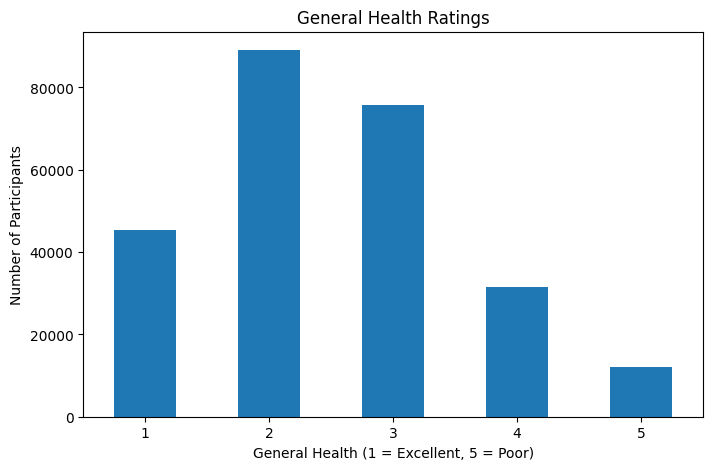

In [12]:
clean_df["GenHlth"].value_counts().sort_index().plot(
    kind="bar", figsize=(8, 5)
)

plt.title("General Health Ratings")
plt.xlabel("General Health (1 = Excellent, 5 = Poor)")
plt.ylabel("Number of Participants")
plt.xticks(rotation=0)

plt.show()

## Step 8: Key Findings and Observations

1. The dataset contains health-related information about survey participants.
2. BMI values show variation among participants.
3. Participants are divided into different diabetes categories.
4. Diabetes status can be compared across blood pressure groups.
5. General health ratings vary among participants.

Note: These observations should be checked and refined using the actual chart results.

## Step 9: Data Ethics and Bias Analysis

1. The dataset represents survey participants and may not represent the entire population.
2. Some age, income, education, or sex groups may be underrepresented.
3. Predictions may be less reliable for groups with fewer survey participants.
4. Income can introduce socioeconomic bias and should be used carefully.
5. Healthcare predictions should support, not replace, professional medical decisions.

## Step 10: Final Dataset Verification

In [13]:
print("Final Dataset Shape:", clean_df.shape)
print("Total Missing Values:", clean_df.isnull().sum().sum())
print("Number of BMI Outliers:", len(outliers))

print("\nFinal Dataset Preview:")
display(clean_df.head())

print("\nAssignment 03 processing completed!")

Final Dataset Shape: (253680, 22)
Total Missing Values: 0
Number of BMI Outliers: 9847

Final Dataset Preview:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0



Assignment 03 processing completed!
